# Imports 

In [1]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from skopt import BayesSearchCV
from sklearn.metrics import confusion_matrix
import joblib
# from sklvq import GLVQ
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.compose import ColumnTransformer

random_state=42

In [2]:
np.int = int
from sklvq import GLVQ

-----

# Functions

In [5]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [6]:
from scipy import stats
def confidence_interval(data, confidence=0.95):
    mean = np.mean(data)
    n = len(data)
    std_err = np.std(data, ddof=1) / np.sqrt(n)
    t_value = stats.t.ppf((1 + confidence) / 2, n - 1)
    margin_of_error = t_value * std_err

    return f"{mean:.5f} ± {margin_of_error:.5f}"

In [7]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]

    best_param = model.steps[-1][-1].best_params_
    print(f"Best parameters: {best_param}")
    print(f"Cross Validation accuracy Array: {accuracy_best_param_cv}")
    print(f"Validation accuracy: {confidence_interval(accuracy_best_param_cv)}")
    
    print(f"Cross Validation precision Array: {precision_best_param_cv}")
    print(f"Validation precision: {confidence_interval(precision_best_param_cv)}")
    
    print(f"Cross Validation recall Array: {recall_best_param_cv}")
    print(f"Validation recall: {confidence_interval(recall_best_param_cv)}")
    
    print(f"Cross Validation f1 Array: {f1_best_param_cv}")
    print(f"Validation f1: {confidence_interval(f1_best_param_cv)}")
    
    print(f"Cross Validation roc Array: {roc_best_param_cv}")
    print(f"Validation roc: {confidence_interval(roc_best_param_cv)}")
    
    print()
    y_train_pred = model.predict(X_train)
    y_valid_pred = model.predict(X_valid)
    y_test_pred = model.predict(X_test)
    
    y_train_proba = model.predict_proba(X_train)[:,1]
    y_valid_proba = model.predict_proba(X_valid)[:,1]
    y_test_proba = model.predict_proba(X_test)[:,1]
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print(f"Train ROC-AUC: {roc_auc_score(y_train, y_train_proba,):.3f}")
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print(f"Validation ROC-AUC: {roc_auc_score(y_valid, y_valid_proba, ):.3f}")
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_proba,):.3f}")
    
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [8]:
def save_model(model, model_name):
    joblib.dump(model, f"{model_name}.joblib")

# Read Dataset

In [9]:
df = pd.read_csv("weatherAUS.csv").dropna(how="any").drop(columns=["Date", "Location"])

_, X, _, y = train_test_split(
    df.drop(columns=["RainTomorrow"]), 
    df[["RainTomorrow"]], test_size=0.5,
    random_state=random_state,
    stratify=df[["RainTomorrow"]]
)

# X = df.drop(columns=["RainTomorrow"])
# y = df[["RainTomorrow"]]

In [10]:
y.value_counts(dropna=False)

RainTomorrow
No              21997
Yes              6213
Name: count, dtype: int64

# Descritive statistics

In [11]:
X.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000,28210.000000
mean,13.438568,24.191159,2.131258,5.496558,7.726827,40.831443,15.638710,19.754165,65.880716,49.638674,1017.267107,1014.830365,4.255619,4.333002,18.176756,22.685268
std,6.425634,6.950843,7.107801,3.663552,3.765211,13.275581,8.301703,8.531421,18.485895,20.242318,6.915814,6.875205,2.796574,2.649385,6.561516,6.819260
min,-5.800000,4.100000,0.000000,0.000000,0.000000,9.000000,2.000000,2.000000,1.000000,0.000000,982.900000,981.200000,0.000000,0.000000,-0.700000,3.700000
25%,8.500000,18.700000,0.000000,2.800000,5.000000,31.000000,9.000000,13.000000,55.000000,35.000000,1012.700000,1010.100000,1.000000,2.000000,13.100000,17.400000
50%,13.200000,23.900000,0.000000,5.000000,8.700000,39.000000,15.000000,19.000000,67.000000,51.000000,1017.200000,1014.700000,5.000000,5.000000,17.800000,22.300000
75%,18.400000,29.600000,0.600000,7.400000,10.700000,48.000000,20.000000,26.000000,79.000000,63.000000,1021.900000,1019.500000,7.000000,7.000000,23.275000,27.900000
max,31.400000,47.300000,183.000000,81.200000,14.500000,117.000000,67.000000,76.000000,100.000000,100.000000,1040.400000,1038.900000,8.000000,8.000000,39.400000,45.800000


In [12]:
pd.options.display.max_columns = 30
X.head(5)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday
23352,17.6,23.1,2.8,4.0,7.2,W,54.0,W,SW,24.0,22.0,71.0,68.0,1013.8,1013.2,1.0,7.0,21.5,21.4,Yes
137779,10.3,34.9,0.0,14.2,12.8,E,41.0,E,SSE,24.0,15.0,5.0,4.0,1017.5,1012.3,0.0,1.0,26.6,33.2,No
23671,18.2,24.7,0.0,5.0,9.8,WSW,30.0,SW,SSW,9.0,19.0,65.0,71.0,1015.6,1014.0,2.0,3.0,22.8,23.1,No
36205,9.3,15.4,3.6,2.6,2.2,SSW,37.0,NW,SSE,11.0,19.0,78.0,68.0,1028.9,1026.7,7.0,7.0,11.6,15.0,Yes
93347,24.4,27.5,10.2,4.6,0.1,SE,59.0,ESE,ESE,24.0,24.0,96.0,96.0,1003.7,1002.0,8.0,8.0,24.6,25.4,Yes


In [13]:
y["RainTomorrow"].value_counts(normalize=True)

RainTomorrow
No     0.779759
Yes    0.220241
Name: proportion, dtype: float64

<Axes: >

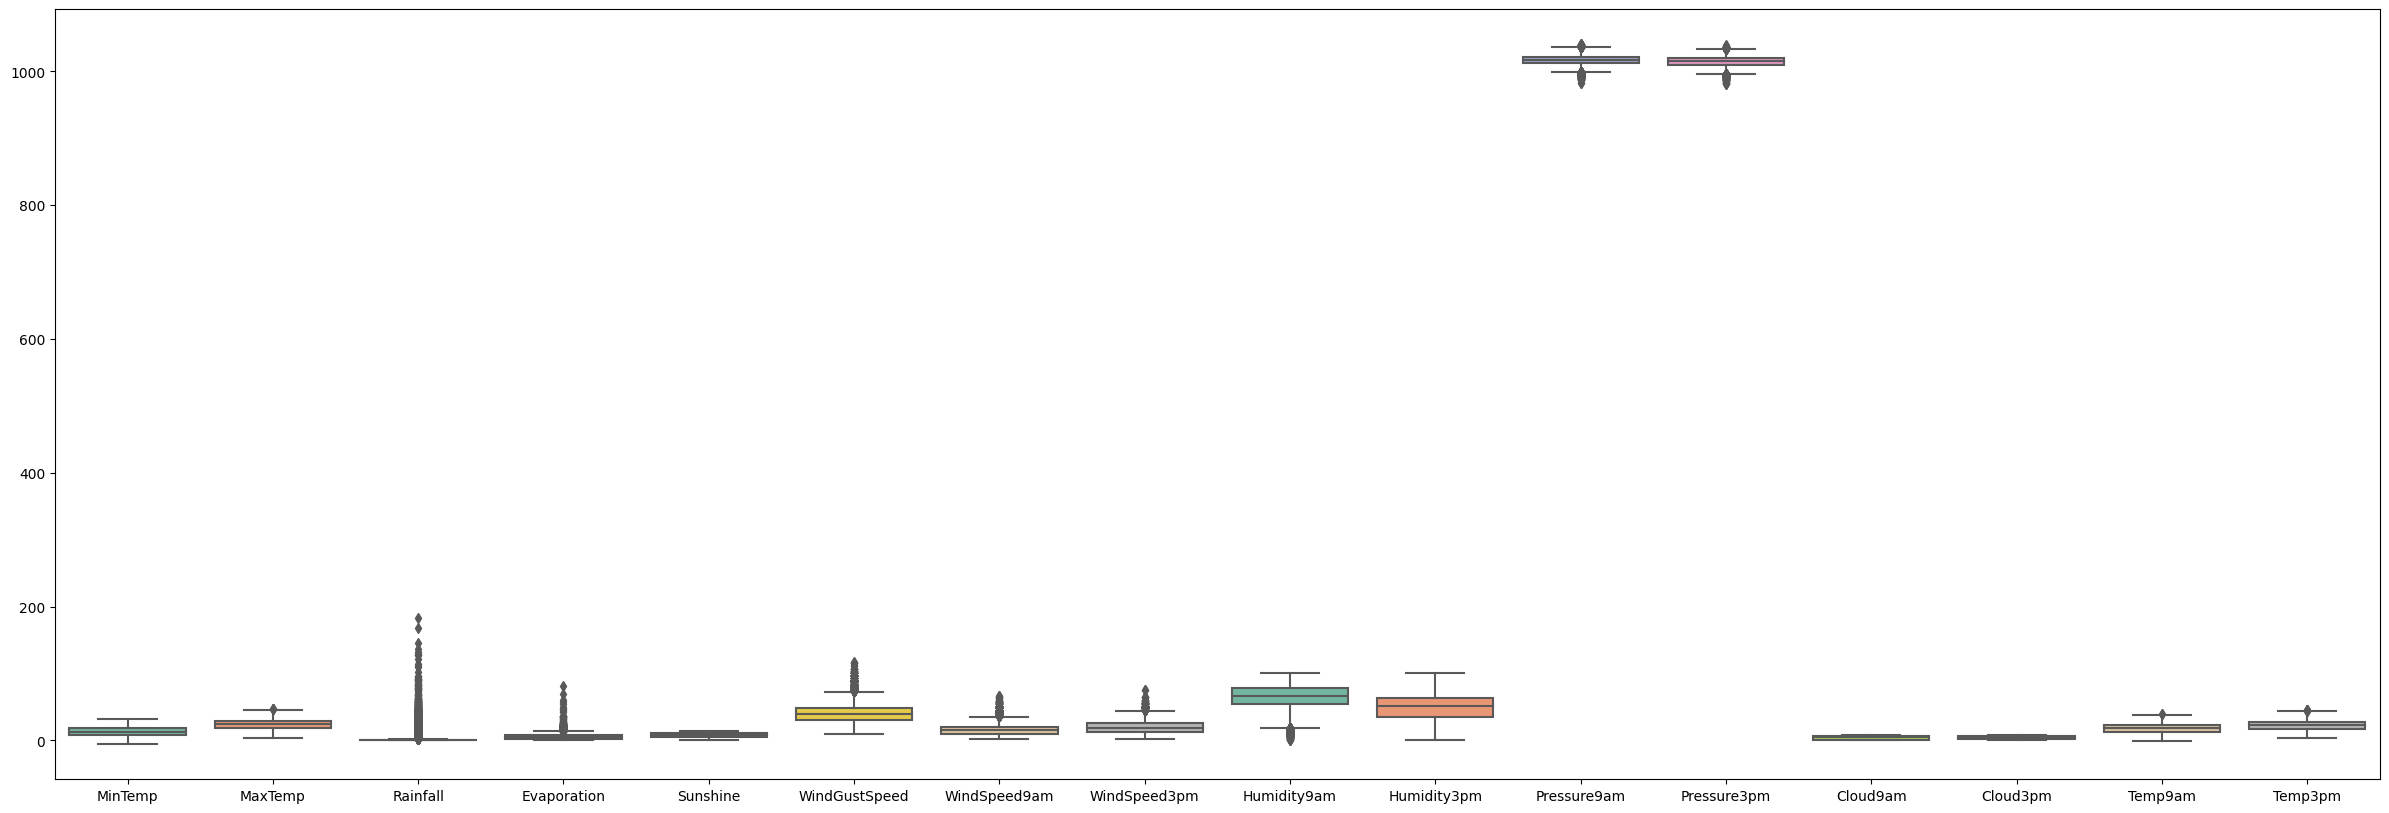

In [14]:
plt.figure(figsize=(30, 10))
sns.boxplot(X, palette="Set2")

## Split Dataset

In [15]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.15, test_size=0.15, random_state=random_state
)

In [16]:
X_train.shape, X_valid.shape, X_test.shape

((19746, 20), (4232, 20), (4232, 20))

# Pre-processing

## Scaling the data

In [17]:
scaler_knn = MinMaxScaler()
scaler_lvq = MinMaxScaler()
scaler_dt = MinMaxScaler()
scaler_rf = MinMaxScaler()
scaler_ada = MinMaxScaler()
scaler_mlp = MinMaxScaler()

## Encoder

In [18]:
encoder = OneHotEncoder(handle_unknown="ignore")

In [19]:
categorical_features = X.select_dtypes(include=["object"]).columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', encoder, categorical_features),
        ('num', MinMaxScaler(), numeric_features)
    ]
)

# Model

## KNN 

In [86]:
cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=random_state)
knn = KNeighborsClassifier()

scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
knn_opt = BayesSearchCV(
    knn,
    {
        "n_neighbors": (1, 80),
        "weights": ["uniform", "distance"],
        "p": (1, 2, 3, 4, 5),
    },
    n_iter=20,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)


pipe_knn = Pipeline([("pp", preprocessor), ("knn", knn_opt)])

In [87]:
pipe_knn.fit(X_train, y_train["RainTomorrow"])

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [80, 1, 'distance'] before, using random point [72, 2, 'distance']
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Pipeline(steps=[('pp',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday'], dtype='object')),
                                                 ('num', MinMaxScaler(),
                                                  Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am',...
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=5, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=KNeighborsClassifier(), n_iter=20,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'n_neighbors': (1, 80),
                                              'p': (1, 2, 3, 4, 5),
                                              'weights': ['uniform',
                                                          'distance']},
                               verbose=1))])

In [97]:
pipe_knn.predict_proba(X_valid)

array([[0.89253718, 0.10746282],
       [0.8968986 , 0.1031014 ],
       [0.73772349, 0.26227651],
       ...,
       [0.33567389, 0.66432611],
       [0.97586539, 0.02413461],
       [0.79698788, 0.20301212]])

In [98]:
y_train["RainTomorrow"]

103252    Yes
33053     Yes
142194    Yes
32446      No
132617    Yes
         ... 
121672    Yes
137823     No
94605      No
75446      No
84205      No
Name: RainTomorrow, Length: 19746, dtype: object

Best parameters: OrderedDict([('n_neighbors', 39), ('p', 1), ('weights', 'distance')])
Cross Validation accuracy Array: [0.82050633 0.81696203 0.81696203 0.82531646 0.82      ]
Validation accuracy: 0.81995 ± 0.00425
Cross Validation precision Array: [0.76863572 0.76114784 0.75767857 0.77854141 0.76850073]
Validation precision: 0.76690 ± 0.01000
Cross Validation recall Array: [0.64077661 0.63314301 0.63685438 0.6508714  0.63880243]
Validation recall: 0.64009 ± 0.00826
Cross Validation f1 Array: [0.66633406 0.65710698 0.66104517 0.67835395 0.66410195]
Validation f1: 0.66539 ± 0.00997
Cross Validation roc Array: [0.84216488 0.83141999 0.83191894 0.84317361 0.83644014]
Validation roc: 0.83702 ± 0.00686

===> Training performance
              precision    recall  f1-score   support

          No    1.00000   1.00000   1.00000     15397
         Yes    1.00000   1.00000   1.00000      4349

    accuracy                        1.00000     19746
   macro avg    1.00000   1.00000   1.00000    

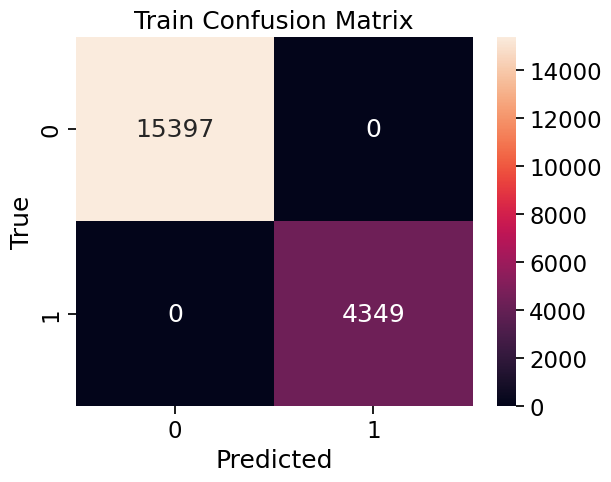

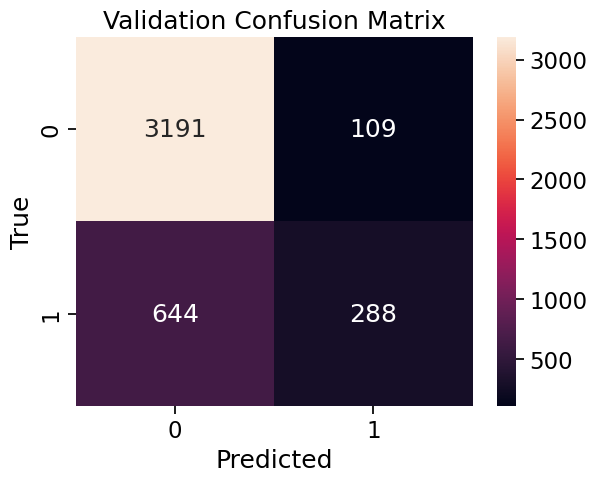

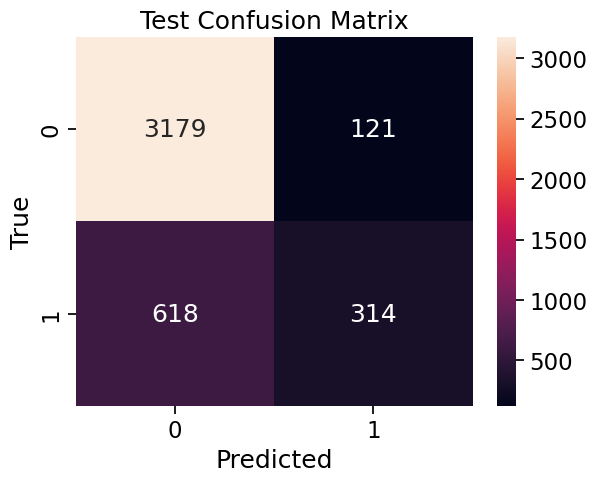

In [102]:
report_model_performance(pipe_knn, X_train, X_valid, X_test, y_train["RainTomorrow"], y_valid["RainTomorrow"], y_test["RainTomorrow"])

In [104]:
save_model(pipe_knn, "knn")

## LVQ

In [34]:
from skopt.space import Integer, Categorical

cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=random_state)
lvq = GLVQ(random_state=random_state)

scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}

lvq_opt = RandomizedSearchCV(
    lvq,
    {
        "prototype_n_per_class": np.arange(1,100).tolist(),
        "distance_type": ["euclidean", "squared-euclidean"],
    },
    n_iter=4,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="ROC-AUC",
    random_state=random_state,
)

pipe_lvq = Pipeline([("pp", preprocessor), ("lvq", lvq_opt)])

In [35]:
pipe_lvq.fit(X_train, y_train["RainTomorrow"])

Fitting 5 folds for each of 4 candidates, totalling 20 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Pipeline(steps=[('pp',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday'], dtype='object')),
                                                 ('num', MinMaxScaler(),
                                                  Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am',...
                                    param_distributions={'distance_type': ['euclidean',
                                                                           'squared-euclidean'],
                                                         'prototype_n_per_class': [1,
                                                                                   2,
                                                                                   3,
                                                                                   4,
                                                                                   5,
                                                                                   6,
                                                                                   7,
                                                                                   8,
                                                                                   9,
                                                                                   10,
                                                                                   11,
                                                                                   12,
                                                                                   13,
                                                                                   14,
                                                                                   15,
                                                                                   16,
                                                                                   17,
                                                                                   18,
                                                                                   19,
                                                                                   20,
                                                                                   21,
                                                                                   22,
                                                                                   23,
                                                                                   24,
                                                                                   25,
                                                                                   26,
                                                                                   27,
                                                                                   28,
                                                                                   29,
                                                                                   30, ...]},
                                    random_state=42, refit='ROC-AUC',
                                    scoring={'Accuracy': 'accuracy',
                                             'F1': 'f1_macro',
                                             'Precision': 'precision_macro',
                                             'ROC-AUC': 'roc_auc_ovr',
                                             'Recall': 'recall_macro'},
                                    verbose=1))])

Best parameters: {'prototype_n_per_class': 43, 'distance_type': 'squared-euclidean'}
Cross Validation accuracy Array: [0.77974684 0.77974684 0.77974684 0.77974684 0.77974684]
Validation accuracy: 0.77975 ± 0.00000
Cross Validation precision Array: [0.38987342 0.38987342 0.38987342 0.38987342 0.38987342]
Validation precision: 0.38987 ± 0.00000
Cross Validation recall Array: [0.5 0.5 0.5 0.5 0.5]
Validation recall: 0.50000 ± 0.00000
Cross Validation f1 Array: [0.43812233 0.43812233 0.43812233 0.43812233 0.43812233]
Validation f1: 0.43812 ± 0.00000
Cross Validation roc Array: [0.83395022 0.82858636 0.81981788 0.83640207 0.82725407]
Validation roc: 0.82920 ± 0.00801

===> Training performance


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, le

              precision    recall  f1-score   support

          No    0.77975   1.00000   0.87625     15397
         Yes    0.00000   0.00000   0.00000      4349

    accuracy                        0.77975     19746
   macro avg    0.38988   0.50000   0.43812     19746
weighted avg    0.60801   0.77975   0.68326     19746

Train ROC-AUC: 0.836
===> Validation performance
              precision    recall  f1-score   support

          No    0.77977   1.00000   0.87626      3300
         Yes    0.00000   0.00000   0.00000       932

    accuracy                        0.77977      4232
   macro avg    0.38989   0.50000   0.43813      4232
weighted avg    0.60805   0.77977   0.68329      4232

Validation ROC-AUC: 0.833
===> Test performance
              precision    recall  f1-score   support

          No    0.77977   1.00000   0.87626      3300
         Yes    0.00000   0.00000   0.00000       932

    accuracy                        0.77977      4232
   macro avg    0.38989   0.500

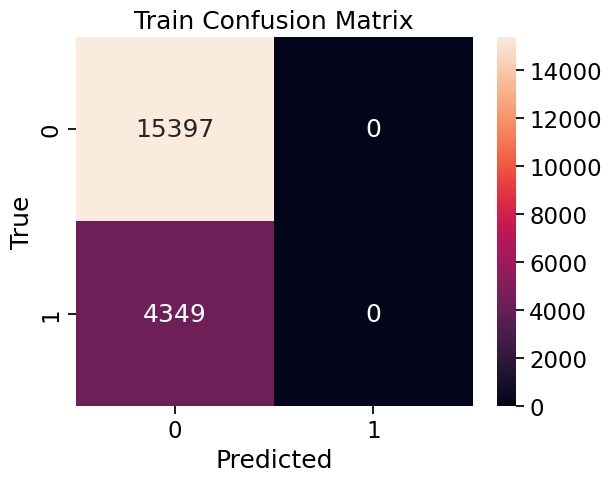

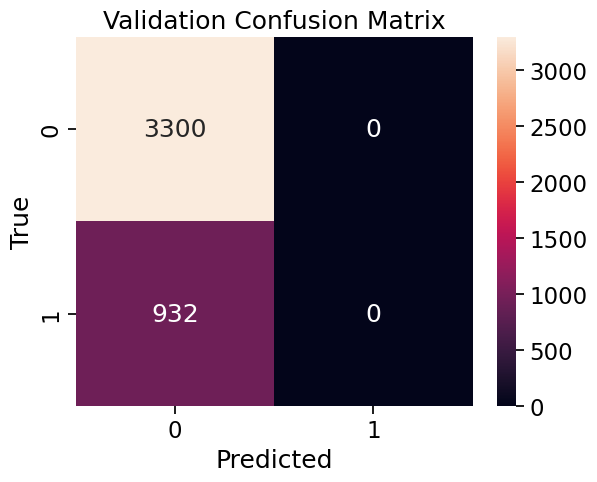

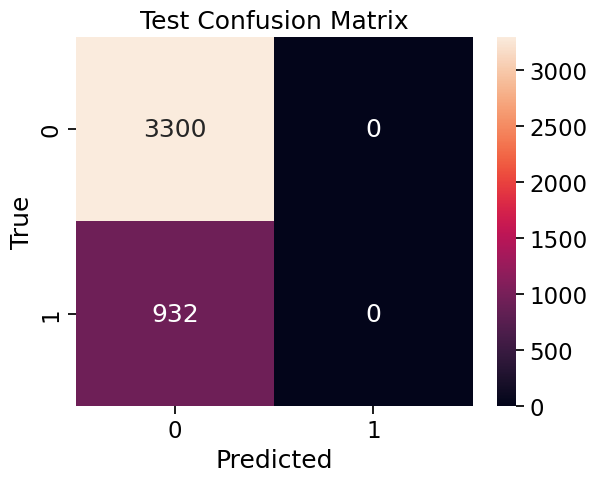

In [38]:
report_model_performance(pipe_lvq, X_train, X_valid, X_test, y_train["RainTomorrow"], y_valid["RainTomorrow"], y_test["RainTomorrow"])

In [37]:
save_model(pipe_lvq, "lvq")

## Decision Tree 

In [123]:
cv = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=random_state)
dt = DecisionTreeClassifier(random_state=random_state)
dt_opt = BayesSearchCV(
    dt,
    {
        "criterion": ["gini", "entropy"],
        "splitter": ["best", "random"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_dt = Pipeline([("pp", preprocessor), ("dt", dt_opt)])

In [124]:
pipe_dt.fit(X_train, y_train["RainTomorrow"])

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits
Fitting 100 folds for each of 1 candidates, totalling 100 fits


Pipeline(steps=[('pp',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday'], dtype='object')),
                                                 ('num', MinMaxScaler(),
                                                  Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am',...
                               estimator=DecisionTreeClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'splitter': ['best', 'random']},
                               verbose=1))])

In [125]:
save_model(pipe_dt, "dt")

Best parameters: OrderedDict([('criterion', 'entropy'), ('max_depth', 100), ('min_samples_leaf', 100), ('min_samples_split', 100), ('splitter', 'best')])
Cross Validation accuracy Array: [0.84379747 0.84405063 0.83848101 0.84025316 0.84607595 0.84025316
 0.85291139 0.84708861 0.85417722 0.84734177 0.84658228 0.84506329
 0.84632911 0.85468354 0.84658228 0.84       0.8443038  0.85139241
 0.84025316 0.84025316 0.84556962 0.84253165 0.84       0.85189873
 0.84379747 0.8521519  0.84303797 0.84126582 0.84303797 0.85164557
 0.84607595 0.85291139 0.83949367 0.84253165 0.84860759 0.85493671
 0.83468354 0.84911392 0.8443038  0.84506329 0.84278481 0.85797468
 0.84556962 0.84303797 0.83620253 0.84202532 0.84481013 0.84506329
 0.84151899 0.84860759 0.8478481  0.84379747 0.84936709 0.8443038
 0.83949367 0.84911392 0.85240506 0.85341772 0.84025316 0.84278481
 0.85139241 0.84556962 0.85265823 0.84506329 0.84734177 0.8478481
 0.85696203 0.84101266 0.84506329 0.8321519  0.84607595 0.84835443
 0.84962025

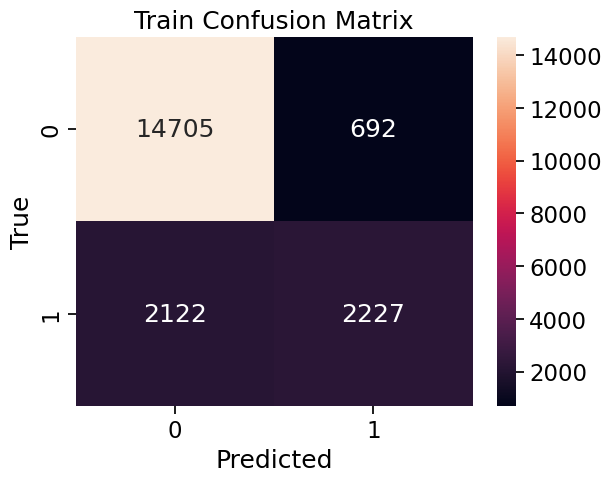

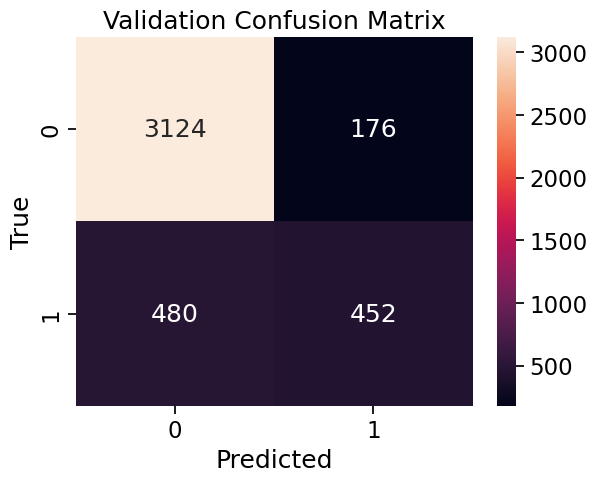

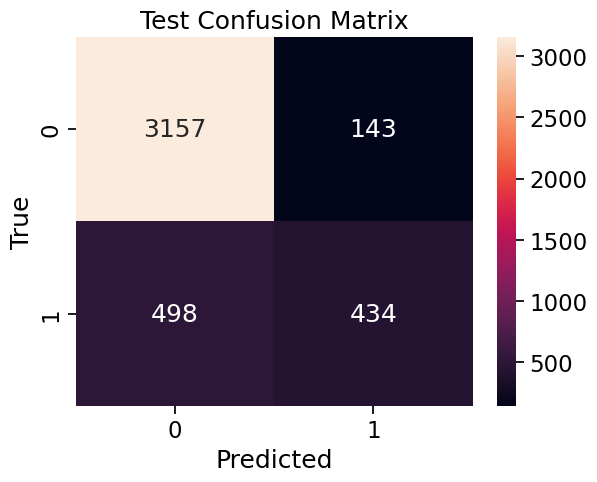

In [130]:
report_model_performance(pipe_dt, X_train, X_valid, X_test, y_train["RainTomorrow"], y_valid["RainTomorrow"], y_test["RainTomorrow"])

## Random Forest

In [138]:
cv = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=random_state)
rf = RandomForestClassifier(random_state=random_state)
rf_opt = BayesSearchCV(
    rf,
    {
        "n_estimators": (1, 1000),
        "criterion": ["gini", "entropy"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
        "max_features": Categorical([None, "sqrt", "log2"]),
    },
    n_iter=10,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_rf = Pipeline([("pp", preprocessor), ("rfr", rf_opt)])

In [139]:
pipe_rf.fit(X_train, y_train["RainTomorrow"])

Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits


Pipeline(steps=[('pp',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday'], dtype='object')),
                                                 ('num', MinMaxScaler(),
                                                  Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am',...
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'max_features': Categorical(categories=(None, 'sqrt', 'log2'), prior=None),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [140]:
save_model(pipe_rf, "rf")

Best parameters: OrderedDict([('criterion', 'entropy'), ('max_depth', 94), ('max_features', None), ('min_samples_leaf', 20), ('min_samples_split', 80), ('n_estimators', 373)])
Cross Validation accuracy Array: [0.85316456 0.85164557 0.84759494 0.85417722 0.85518987 0.85189873
 0.85696203 0.85721519 0.86177215 0.8556962 ]
Validation accuracy: 0.85453 ± 0.00275
Cross Validation precision Array: [0.80625719 0.80227234 0.79934513 0.80626816 0.81351836 0.80685418
 0.81461449 0.82140321 0.82654274 0.81687969]
Validation precision: 0.81140 ± 0.00620
Cross Validation recall Array: [0.73223429 0.73167264 0.71835349 0.73659501 0.73064637 0.72606173
 0.73631885 0.72905844 0.74022802 0.72849679]
Validation recall: 0.73097 ± 0.00440
Cross Validation f1 Array: [0.75863163 0.75714506 0.74574713 0.76202669 0.75918906 0.75384692
 0.76401226 0.75973454 0.77013501 0.75822653]
Validation f1: 0.75887 ± 0.00456
Cross Validation roc Array: [0.88189357 0.87958986 0.87993059 0.88946223 0.88505038 0.8850459
 0.8

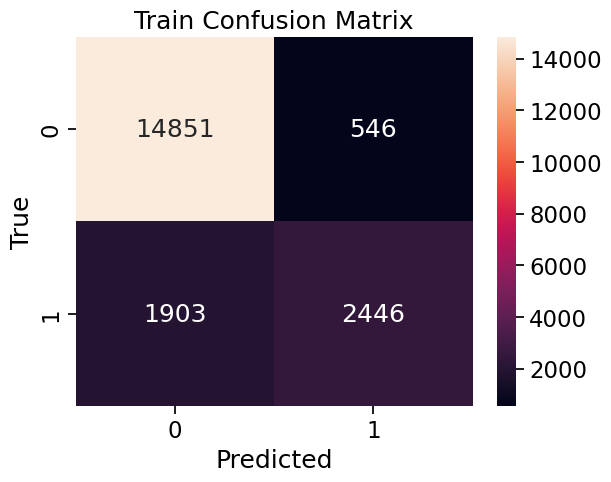

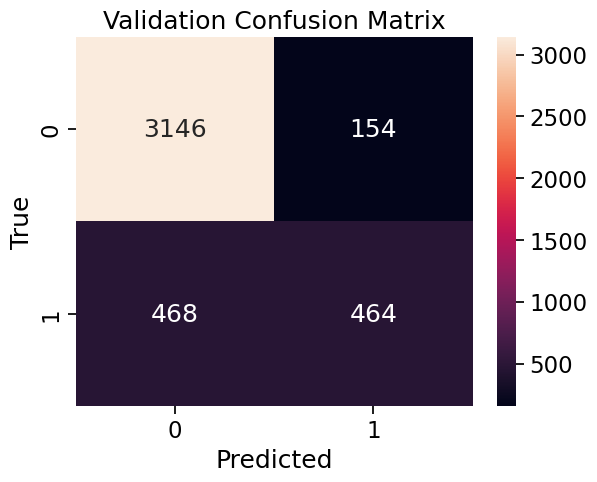

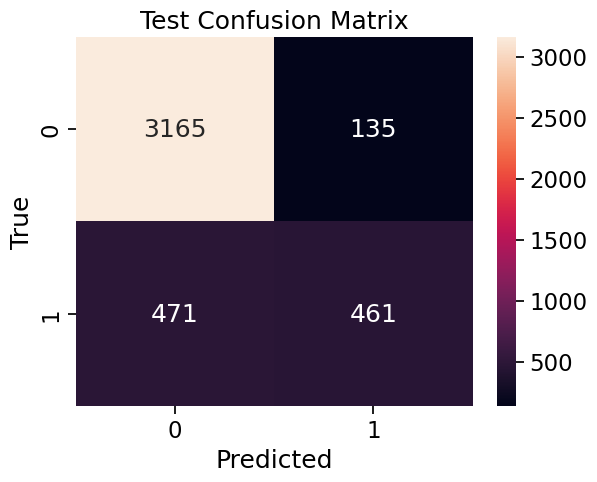

In [143]:
report_model_performance(pipe_rf, X_train, X_valid, X_test, y_train["RainTomorrow"], y_valid["RainTomorrow"], y_test["RainTomorrow"])

## AdaBoost

In [146]:
cv = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=random_state)
ada = AdaBoostClassifier(random_state=random_state)
ada_opt = BayesSearchCV(
    ada,
    {
        "n_estimators": (1, 1000),
        "learning_rate": (0.01, 1),
        "algorithm": ["SAMME", "SAMME.R"],
    },
    n_iter=10,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_opt = Pipeline([("pp", preprocessor), ("ada", ada_opt)])

In [147]:
pipe_opt.fit(X_train, y_train["RainTomorrow"])

Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits
Fitting 10 folds for each of 1 candidates, totalling 10 fits


Pipeline(steps=[('pp',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday'], dtype='object')),
                                                 ('num', MinMaxScaler(),
                                                  Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am',...
            train_size=None),
                               estimator=AdaBoostClassifier(random_state=42),
                               n_iter=10, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'algorithm': ['SAMME', 'SAMME.R'],
                                              'learning_rate': (0.01, 1),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [148]:
save_model(pipe_opt, "ada")

Best parameters: OrderedDict([('algorithm', 'SAMME.R'), ('learning_rate', 0.7776107350396038), ('n_estimators', 360)])
Cross Validation accuracy Array: [0.85316456 0.84911392 0.84582278 0.85721519 0.84582278 0.85417722
 0.85316456 0.85822785 0.85746835 0.85113924]
Validation accuracy: 0.85253 ± 0.00325
Cross Validation precision Array: [0.8009324  0.79254168 0.78931813 0.80361236 0.78848189 0.80348313
 0.80070511 0.8147739  0.80719765 0.8000446 ]
Validation precision: 0.80011 ± 0.00584
Cross Validation recall Array: [0.74089416 0.73705964 0.72670175 0.75545044 0.72835125 0.74113114
 0.74130654 0.74125429 0.74983953 0.73299746]
Validation recall: 0.73950 ± 0.00635
Cross Validation f1 Array: [0.76375598 0.75844697 0.74980475 0.7749687  0.75081779 0.76467678
 0.76399244 0.76792019 0.77216078 0.75756713]
Validation f1: 0.76241 ± 0.00596
Cross Validation roc Array: [0.87723504 0.87427862 0.87670324 0.88638939 0.87453986 0.88589491
 0.89072175 0.88164054 0.87739812 0.87440439]
Validation roc

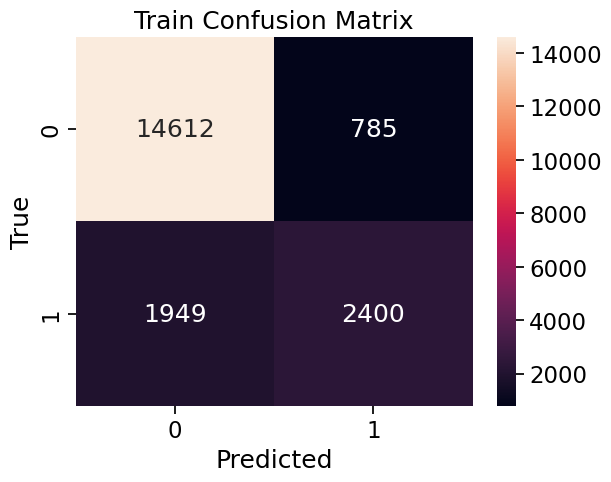

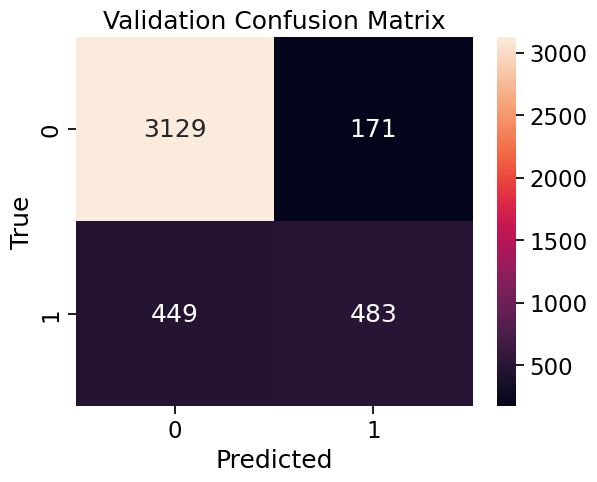

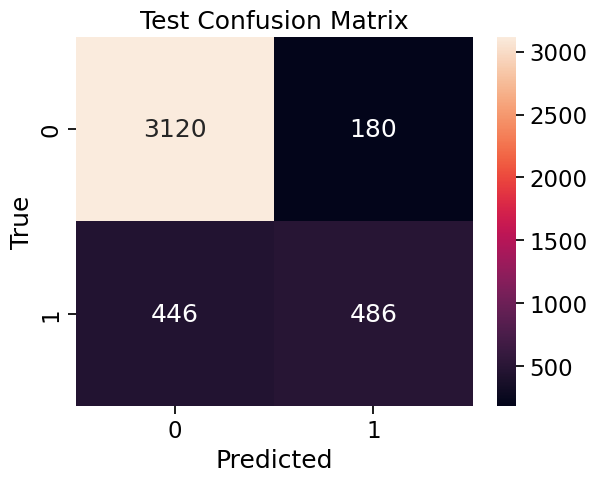

In [150]:
report_model_performance(pipe_opt, X_train, X_valid, X_test, y_train["RainTomorrow"], y_valid["RainTomorrow"], y_test["RainTomorrow"])

## MLP

In [151]:
cv = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=random_state)
mlp = MLPClassifier(random_state=random_state, max_iter=1000)
mlp_opt = RandomizedSearchCV(
    mlp,
    {
        "hidden_layer_sizes": [(5,), (10,), (5, 10), (10, 5), (10, 10)],
        "activation": ["identity", "logistic", "tanh", "relu"],
        "solver": ["lbfgs", "sgd", "adam"],
        "alpha": np.arange(0, 100),
        "learning_rate": ["constant", "invscaling", "adaptive"],
    },
    n_iter=10,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_mlp = Pipeline([("pp", preprocessor), ("mlp", mlp_opt)])

In [153]:
pipe_mlp.fit(X_train, y_train["RainTomorrow"])

Fitting 10 folds for each of 10 candidates, totalling 100 fits


/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/envs/llm/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/matheusalb/anaconda3/e

Pipeline(steps=[('pp',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday'], dtype='object')),
                                                 ('num', MinMaxScaler(),
                                                  Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am',...
       85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]),
                                                         'hidden_layer_sizes': [(5,),
                                                                                (10,),
                                                                                (5,
                                                                                 10),
                                                                                (10,
                                                                                 5),
                                                                                (10,
                                                                                 10)],
                                                         'learning_rate': ['constant',
                                                                           'invscaling',
                                                                           'adaptive'],
                                                         'solver': ['lbfgs',
                                                                    'sgd',
                                                                    'adam']},
                                    random_state=42, refit='Accuracy',
                                    scoring={'Accuracy': 'accuracy',
                                             'F1': 'f1_macro',
                                             'Precision': 'precision_macro',
                                             'ROC-AUC': 'roc_auc_ovr',
                                             'Recall': 'recall_macro'},
                                    verbose=1))])

Best parameters: {'solver': 'lbfgs', 'learning_rate': 'invscaling', 'hidden_layer_sizes': (10, 10), 'alpha': 65, 'activation': 'tanh'}
Cross Validation accuracy Array: [0.85341772 0.84683544 0.85240506 0.86050633 0.84835443 0.84886076
 0.8556962  0.85468354 0.85620253 0.85392405]
Validation accuracy: 0.85309 ± 0.00297
Cross Validation precision Array: [0.80016389 0.78541591 0.80358222 0.81051497 0.79187748 0.7945108
 0.80651409 0.80722226 0.803715   0.80487685]
Validation precision: 0.80084 ± 0.00563
Cross Validation recall Array: [0.74353075 0.74095947 0.7329844  0.7579732  0.73451075 0.7319488
 0.74292991 0.73733206 0.75026496 0.7376698 ]
Validation recall: 0.74101 ± 0.00583
Cross Validation f1 Array: [0.76545336 0.75895867 0.75851317 0.77898    0.756383   0.75523266
 0.76689303 0.76285299 0.77137999 0.76246728]
Validation f1: 0.76371 ± 0.00524
Cross Validation roc Array: [0.88109606 0.87668271 0.88225444 0.88640357 0.87874608 0.88982572
 0.89114681 0.88503545 0.8818458  0.8759897 ]


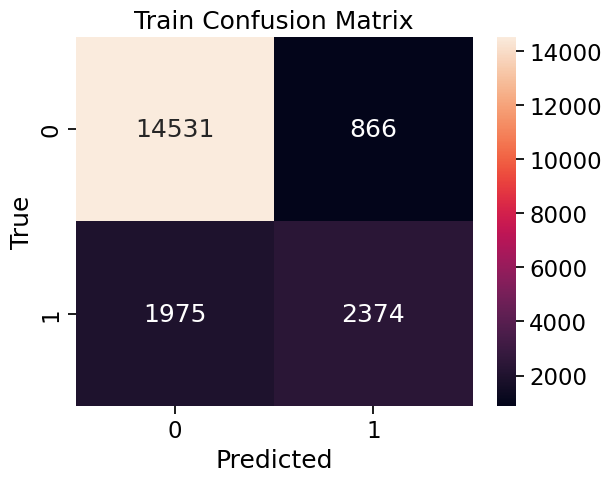

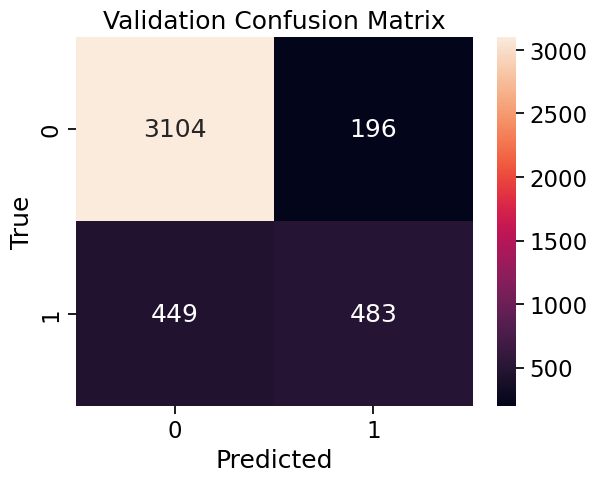

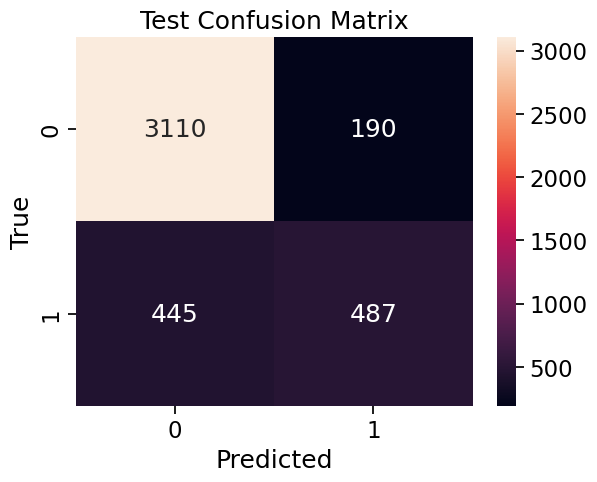

In [154]:
report_model_performance(pipe_mlp, X_train, X_valid, X_test, y_train["RainTomorrow"], y_valid["RainTomorrow"], y_test["RainTomorrow"])

In [155]:
save_model(pipe_mlp, "mlp")